
# 🔄 Transfer Learning in Deep Learning (CNN)

---

## 1. Executive Summary

**Transfer Learning** is a powerful machine learning paradigm where knowledge (pre-trained weights and learned visual representations) gained from solving one task on a large benchmark dataset (e.g., ImageNet) is repurposed and applied to a different, but related, target task.

As prominent AI researchers like Andrew Ng have noted, Transfer Learning has become a primary driver of industrial deep learning applications because it solves two critical bottlenecks:

1. **Data Scarcity:** Eliminates the need for massive labeled custom datasets.
2. **Computational Constraints:** Reduces training time from days to minutes by reusing existing low-level feature extractors instead of training networks from scratch.

---

## 2. Core Architecture: Convolution Base vs. Classifier

A standard Convolutional Neural Network (CNN) consists of two main functional blocks:

### CNN Architecture

```text
Input Image
     |
     ▼
[ Convolutional Base (Feature Extractor) ]
     |
     ▼
[ Dense Head (Classifier) ]
     |
     ▼
Output

Convolutional Base:
├── Conv2D + Activation
└── MaxPooling

Dense Classifier Head:
├── Flatten / Pooling
├── Dense (Fully Connected)
└── Softmax / Sigmoid
````

- Convolutional Base: The series of Conv2D and Pooling layers. Responsible for extracting spatial features (edges, textures, shapes). Early layers learn generic features (edges/lines), while deeper layers capture complex, domain-specific shapes.
- Dense Classifier Head: The fully connected layers placed on top of the convolutional base. Responsible for mapping extracted spatial features to final class probability predictions.

## 3. Two Primary Strategies of Transfer Learning

Depending on the size of your target dataset and its similarity to the source dataset (ImageNet), Transfer Learning is implemented using two strategies:

### Strategy Selection Flowchart

```
                 Which Strategy to Use?
                          |
             ┌────────────┴────────────┐
             ▼                         ▼
 High Dataset Similarity       Low Dataset Similarity
        / Small Data               / Larger Data
             |                         |
             ▼                         ▼
 Feature Extraction              Fine-Tuning
             |                         |
             ▼                         ▼
 Freeze Entire Conv Base       Freeze Early Conv Layers
             |                         |
             ▼                         ▼
 Train Dense Head Only         Unfreeze Deep Conv Layers
                                      +
                               Train Dense Head
```

### Strategy A: Feature Extraction

- Mechanism: The entire convolutional base of the pre-trained model (e.g., VGG16) is frozen (`conv_base.trainable = False`). Only the newly attached Dense classification head is trained on the target dataset.
- When to Use: Ideal when the custom target dataset is small and visually similar to ImageNet categories (e.g., Cats vs. Dogs).
- Advantage: Fast training with zero risk of destroying pre-trained weights.

### Strategy B: Fine-Tuning

- Mechanism: The early convolutional layers remain frozen, while the deeper convolutional layers (e.g., `block5_conv1` onward in VGG16) are unfrozen (`trainable = True`) alongside the Dense head. The entire unblocked pipeline is trained at a very low learning rate (e.g., `1e-5` or RMSprop).
- When to Use: Ideal when the target dataset is large or significantly different from ImageNet categories (e.g., medical X-rays or specialized industrial components).
- Advantage: Adapts high-level feature detectors specifically to the target domain, yielding higher accuracy.

## 4. Performance Comparison Summary (Cat vs. Dog Benchmark)

| Approach                   | Training Setup                                    | Typical Validation Accuracy | Key Observations                                                                         |
| -------------------------- | ------------------------------------------------- | --------------------------- | ---------------------------------------------------------------------------------------- |
| Custom CNN from Scratch    | 3 Conv Layers built from scratch                  | $\approx 81%$               | Slow convergence; prone to severe overfitting without heavy regularization.              |
| Feature Extraction (VGG16) | Frozen VGG16 Conv Base + New Dense Head           | $\approx 90 - 91.4%$        | Fast convergence; stable performance; accuracy increases further with Data Augmentation. |
| Fine-Tuning (VGG16)        | Frozen Blocks 1-4 + Unfrozen Block 5 & Dense Head | $\approx 95.2%$             | Highest performance; fine-tunes deep feature detectors specifically for the target task. |

```
```

In [1]:
import tensorflow 
from tensorflow import keras 
from keras import Sequential 
from keras.layers import Dense, Input, Flatten
from keras.applications.vgg16 import VGG16

I0000 00:00:1794059877.415876     489 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794059877.728729     489 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794059879.464142     489 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
conv_base = VGG16(
    weights='imagenet', 
    include_top = False, 
    input_shape=(150,150,3)
)

I0000 00:00:1794059943.025687     489 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 16s 0us/step


In [3]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model = Sequential([
    conv_base, 
    Flatten(), 
    Dense(256,activation='relu'), 
    Dense(1,activation='sigmoid')
]) 

In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 16,812,353 (64.13 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Trainable params are now approx ~16M , we will not change the weights of convolutional layers 
# , we need to upadte only FC part and use the Conv part as default

conv_base.trainable = False 

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [8]:
# now the trainable are : ~16M -> ~2M 

In [11]:
# Generators 
train_ds = keras.utils.image_dataset_from_directory(
    directory='train', 
    labels='inferred', 
    label_mode='int', 
    batch_size = 32, 
    image_size = (150,150)
)

test_ds = keras.utils.image_dataset_from_directory(
    directory='test', 
    labels='inferred', 
    label_mode='int', 
    batch_size = 32, 
    image_size = (150,150)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [12]:
# Normalise 
def process(image,label): 
    image = tensorflow.cast(image/225. , tensorflow.float32) 
    return image,label 

train_ds = train_ds.map(process )
validation_ds = test_ds.map(process)

In [14]:
model.compile(
    optimizer='adam', 
    loss='binary_crossentropy', 
    metrics=['accuracy']
)

In [15]:
history = model.fit(train_ds, epochs=10, validation_data = validation_ds)

Epoch 1/10


/home/shubham/dl-gpu/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794060863.739000     629 service.cc:153] XLA service 0x78ff54047750 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794060863.739062     629 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.0)
I0000 00:00:1794060863.780901     629 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794060864.104554     629 cuda_dnn.cc:461] Loaded cuDNN version 92800
I0000 00:00:1794060864.130192     629 dot_merger.cc:481]

  3/625 ━━━━━━━━━━━━━━━━━━━━ 28s 45ms/step - accuracy: 0.5833 - loss: 1.6919   

I0000 00:00:1794060881.810822     629 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 66ms/step - accuracy: 0.8892 - loss: 0.2601 - val_accuracy: 0.9160 - val_loss: 0.2030
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.9298 - loss: 0.1717 - val_accuracy: 0.9204 - val_loss: 0.1950
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.9395 - loss: 0.1484 - val_accuracy: 0.9186 - val_loss: 0.2037
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.9530 - loss: 0.1184 - val_accuracy: 0.9196 - val_loss: 0.2185
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.9646 - loss: 0.0912 - val_accuracy: 0.9186 - val_loss: 0.2460
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.9693 - loss: 0.0781 - val_accuracy: 0.9004 - val_loss: 0.3660
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.9804 - loss: 0.0533 - val_accuracy: 0.9104 - val_loss: 0.3466
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.9790 - loss: 0.0528 - val_accurac

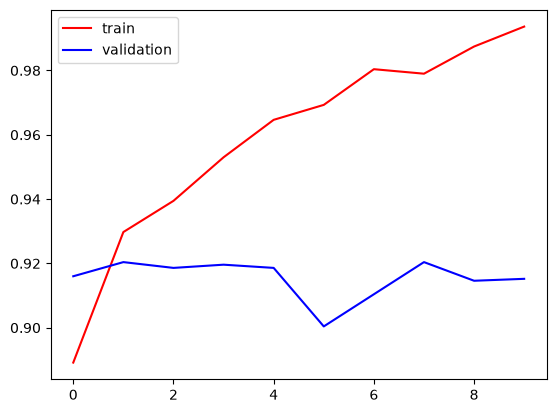

In [16]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

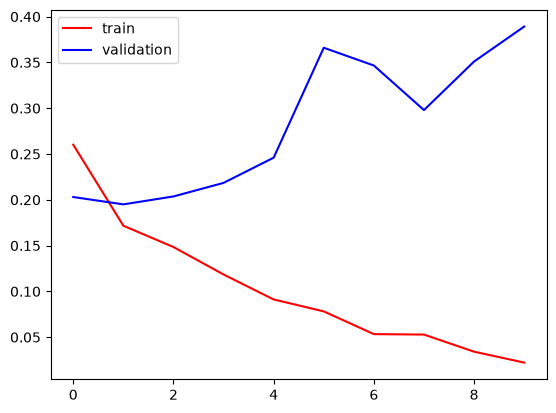

In [17]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

# By using Data Augmentation 

In [18]:
conv_base = VGG16(
    weights='imagenet',
    include_top = False,
    input_shape=(150,150,3)
)

In [19]:
model1 = Sequential([
    conv_base, 
    Flatten(), 
    Dense(256,activation='relu'), 
    Dense(1,activation='sigmoid')
]) 

In [20]:
conv_base.trainable = False

In [21]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [23]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

In [24]:
batch_size = 32

train_datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
        'train',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary') 

validation_generator = test_datagen.flow_from_directory(
        'test',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary')

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [25]:
model1.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

In [27]:
history1 = model1.fit(
        train_generator,
        epochs=10,
        validation_data=validation_generator)

Epoch 1/10


I0000 00:00:1794061377.587355     489 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1794061378.683094     629 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_35811__.61


625/625 ━━━━━━━━━━━━━━━━━━━━ 196s 310ms/step - accuracy: 0.8648 - loss: 0.3109 - val_accuracy: 0.9120 - val_loss: 0.2140
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 214s 342ms/step - accuracy: 0.8958 - loss: 0.2391 - val_accuracy: 0.9078 - val_loss: 0.2144
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 203s 325ms/step - accuracy: 0.9068 - loss: 0.2203 - val_accuracy: 0.9158 - val_loss: 0.1983
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 207s 331ms/step - accuracy: 0.9083 - loss: 0.2113 - val_accuracy: 0.9106 - val_loss: 0.2178
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 186s 297ms/step - accuracy: 0.9150 - loss: 0.1995 - val_accuracy: 0.9086 - val_loss: 0.2165
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 283s 453ms/step - accuracy: 0.9170 - loss: 0.1942 - val_accuracy: 0.9194 - val_loss: 0.1961
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 271s 433ms/step - accuracy: 0.9211 - loss: 0.1869 - val_accuracy: 0.9208 - val_loss: 0.1821
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 296s 473ms/step - accuracy: 0.9257 - loss: 0.17

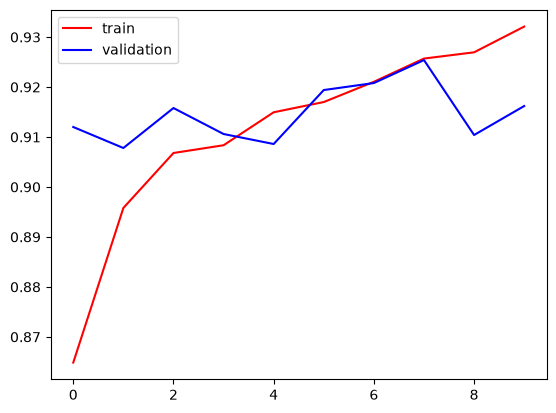

In [31]:
import matplotlib.pyplot as plt

plt.plot(history1.history['accuracy'],color='red',label='train')
plt.plot(history1.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

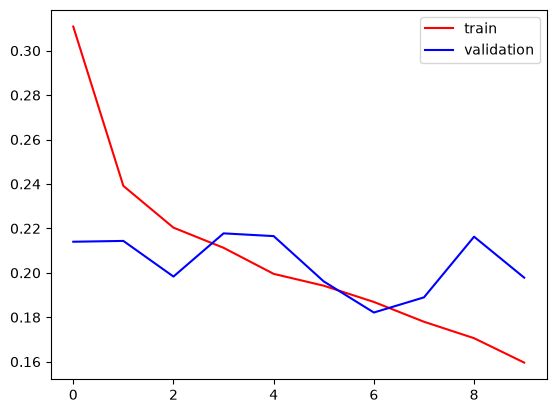

In [30]:
plt.plot(history1.history['loss'],color='red',label='train')
plt.plot(history1.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
# data augmentation had imporved the test accuract from 90 -> 91% ,   